# VENTURETRACK — INDIAN STARTUP FUNDING INTELLIGENCE
## Academic Exploratory Data Analysis & Feature Engineering Workbench
**Course**: Data Engineering & Analytics | **Deliverable**: Mini Project 13  
**Author / Student**: Richa Sharma (**Registration No**: 25BAI10049)  
**Tagline**: *Understand Funding. Discover Patterns. Evaluate Opportunities.*  

---

### Project Overview & Problem Statement
VentureTrack is an institutional-grade investment research intelligence platform built to evaluate the Indian startup funding ecosystem. This Jupyter Notebook serves as an independent, reproducible academic deliverable demonstrating all five core feature engineering tasks required in Mini Project 13:

1. **Task 1: Adding and Removing Columns**  
   - `funding_crores` = `funding_amount * 83 / 10,000,000` (rounded to 2 decimal places)
   - `is_bengaluru`: Boolean flag identifying entities in Bengaluru (normalizing 'Bangalore', 'Bengaluru')
   - `investor_count`: Initialized explicitly with `np.nan` (safeguard against fabricated data)
   - Dropping standardized working column `funding_amount` and confirming absence in `df.columns`.

2. **Task 2: apply() and map() Transformations**  
   - `round_number` via `apply()` and lambda with Series A=1 through Series F=6 (other/unmapped = 0)
   - `sector_category` via `map()` with the assignment mapping dictionary and 'Other / Unmapped' fallback
   - `headline` via `DataFrame.apply(axis=1)` formatted as `Startup raised ₹X Cr in Round Y`.

3. **Task 3: Binning with cut() and qcut()**  
   - `funding_tier` via `pd.cut()`: Small (<₹100 Cr), Mid (₹100-300 Cr), Large (>₹300 Cr)
   - `funding_quartile` via `pd.qcut()`: Q1, Q2, Q3, Q4 with duplicate boundary handling
   - Side-by-side comparison matrix and empirical divergence analysis.

4. **Task 4: Date and Time Feature Extraction**  
   - Calendar attributes: `year`, `month`, `quarter`, `day_of_week` (Monday = 0), `month_name`
   - Dynamic `days_since_funding` using `pd.Timestamp.today()`
   - `funding_era` via `pd.cut()`: Early (Pre-2020), Pandemic (2020-2021), Recovery (2022+).

5. **Task 5: Summary Metrics**  
   - Sector & city ranking aggregations
   - Group peer benchmark via `groupby().transform('mean')`, creating `sector_avg` and `above_sector_avg`
   - Rigorous four-to-five sentence interpretation of actual findings.

All calculations are performed dynamically using pure Python and pandas without external dashboard dependencies.

## 2. Library Imports
We import foundational data engineering, statistical, and plotting libraries adhering to reproducible standards.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from datetime import datetime
from pathlib import Path

# Set global styling
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'sans-serif'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
print('Libraries imported successfully.')

Libraries imported successfully.


## 3. Dataset Loading
We load the Indian Startup Funding source dataset from the relative repository path `../data/startup_funding_raw.csv`.

In [2]:
data_path = Path('../data/startup_funding_raw.csv')
if not data_path.exists():
    data_path = Path('data/startup_funding_raw.csv')

raw_df = pd.read_csv(data_path)
print(f'Raw dataset loaded successfully.')
print(f'Dimensions: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns.')

Raw dataset loaded successfully.
Dimensions: 3,044 rows × 10 columns.


## 4. Initial Data Inspection
We inspect raw column headers, sample records, and evaluate missing value frequency across attributes.

In [3]:
print('Raw Column Names:')
print(list(raw_df.columns))

null_audit = pd.DataFrame({
    'Data Type': raw_df.dtypes,
    'Null Count': raw_df.isnull().sum(),
    'Null Pct (%)': (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
})
print('\nMissing Value Diagnostic Report:')
print(null_audit)

Raw Column Names:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']

Missing Value Diagnostic Report:
                  Data Type  Null Count  Null Pct (%)
Sr No                 int64           0          0.00
Date dd/mm/yyyy      object           0          0.00
Startup Name         object           0          0.00
Industry Vertical    object         171          5.62
SubVertical          object         936         30.75
City  Location       object         180          5.91
Investors Name       object          24          0.79
InvestmentnType      object           4          0.13
Amount in USD        object         960         31.54
Remarks              object        2625         86.24


## 5. Data Cleaning & Internal Schema Standardization
We map disparate raw column names to canonical internal schema names: `startup_name`, `city`, `funding_amount`, `funding_round`, `sector`, and `date`. We sanitize unicode escape artifacts (`\xc2\xa0`), strip commas from currency, and parse Indian dates formatted primarily as `%d/%m/%Y`.

In [4]:
# Column Mapping
col_map = {
    'Sr No': 'sr_no',
    'Date dd/mm/yyyy': 'date',
    'Startup Name': 'startup_name',
    'Industry Vertical': 'sector',
    'SubVertical': 'sub_sector',
    'City  Location': 'city',
    'Investors Name': 'investors_name',
    'InvestmentnType': 'funding_round',
    'Amount in USD': 'funding_amount',
    'Remarks': 'remarks'
}
df_clean = raw_df.rename(columns=col_map).copy()

# Text sanitization
def sanitize_text(val):
    if pd.isna(val): return np.nan
    s = re.sub(r'\\+xc2\\+xa0|\\xc2\\xa0|\xa0', ' ', str(val))
    s = re.sub(r'\\n|\\r', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return np.nan if s.lower() in ['nan', 'none', 'null', ''] else s

for col in ['startup_name', 'city', 'sector', 'funding_round']:
    df_clean[col] = df_clean[col].apply(sanitize_text)

# Numeric USD parse
def parse_amount(val):
    if pd.isna(val): return np.nan
    s = re.sub(r'\\+xc2\\+xa0|\\xc2\\xa0|\xa0|[ ,\+\$]', '', str(val)).strip().lower()
    if s in ['undisclosed', 'unknown', 'n/a', 'nan', '']:
        return np.nan
    try:
        amt = float(s)
        return amt if amt >= 0 else np.nan
    except:
        return np.nan

df_clean['funding_amount'] = df_clean['funding_amount'].apply(parse_amount)

# Date parse
def parse_date(val):
    if pd.isna(val): return pd.NaT
    s = re.sub(r'\\+xc2\\+xa0|\\xc2\\xa0|\xa0', '', str(val)).strip()
    s = s.replace('//', '/').replace('.', '/')
    if s == '05/072018': s = '05/07/2018'
    elif s == '01/07/015': s = '01/07/2015'
    return pd.to_datetime(s, format='%d/%m/%Y', errors='coerce')

df_clean['date'] = df_clean['date'].apply(parse_date)
df_clean['city'] = df_clean['city'].fillna('Unknown').apply(lambda c: c.split('/')[0].strip() if '/' in str(c) else str(c))
df_clean['sector'] = df_clean['sector'].fillna('Unspecified')
df_clean['funding_round'] = df_clean['funding_round'].fillna('Unknown')
print('Data cleaned. Disclosed funding amounts parsed:', df_clean['funding_amount'].notna().sum())

Data cleaned. Disclosed funding amounts parsed: 2073


## 6. Task 1 — Adding and Removing Columns

In Task 1, we implement:
1. `funding_crores` = `funding_amount * 83 / 10_000_000`, rounded to two decimal places (fixed ₹83/USD exchange rate).
2. `is_bengaluru`: Boolean flag identifying entities in Bengaluru (normalizing 'Bangalore', 'Bengaluru').
3. `investor_count`: Initialized explicitly with `np.nan` (safeguard against fabricated data).
4. Drop standardized working column `funding_amount` and verify absence in `df.columns`.

### Theoretical Justification: When to Drop vs Retain a Raw Feature
- **When to Drop**: When the derived feature is an exact, deterministic linear scalar multiple of the original column (e.g., funding_crores at ₹83/USD), keeping both introduces severe multi-collinearity and doubles memory usage. Dropping `funding_amount` establishes INR Crores as the single domestic reporting standard.
- **When to Retain**: When the conversion is lossy (e.g. continuous amounts into categorical tiers) or subject to time-varying parameters (e.g. historical floating FX rates), retaining the raw input is mandatory for auditability.

In [5]:
# 1. funding_crores
USD_TO_INR = 83.0
df_clean['funding_crores'] = (df_clean['funding_amount'] * USD_TO_INR / 10_000_000).round(2)

# 2. is_bengaluru
blr_variants = {'bangalore', 'bengaluru'}
df_clean['is_bengaluru'] = df_clean['city'].apply(
    lambda c: bool(any(v in str(c).strip().lower() for v in blr_variants))
).astype(bool)

# 3. investor_count initialized with NaN
df_clean['investor_count'] = np.nan

# 4. Drop working column funding_amount
df_clean = df_clean.drop(columns=['funding_amount'])

print('Explicit Confirmation: Is funding_amount present in columns?', 'funding_amount' in df_clean.columns)
print('\nCurrent DataFrame Columns:')
print(list(df_clean.columns))
print('\nTask 1 Sample Records:')
print(df_clean[['startup_name', 'city', 'funding_crores', 'is_bengaluru', 'investor_count']].head(5))

Explicit Confirmation: Is funding_amount present in columns? False

Current DataFrame Columns:
['sr_no', 'date', 'startup_name', 'sector', 'sub_sector', 'city', 'investors_name', 'funding_round', 'remarks', 'funding_crores', 'is_bengaluru', 'investor_count']

Task 1 Sample Records:
                   startup_name       city  funding_crores  is_bengaluru  investor_count
0                        BYJU’S  Bengaluru         1660.00          True             NaN
1                        Shuttl    Gurgaon           66.80         False             NaN
2                     Mamaearth  Bengaluru          152.38          True             NaN
3  https://www.wealthbucket.in/  New Delhi           24.90         False             NaN
4                        Fashor     Mumbai           14.94         False             NaN


## 7. Task 2 — apply() and map() Transformations

1. Create `round_number` using `apply()` and a lambda mapping Series A-F to integers 1-6 (other/unmapped = 0).
2. Create `sector_category` using `map()` and the assignment dictionary, with unmatched sectors falling back to 'Other / Unmapped'.
3. Create `headline` using `DataFrame.apply(axis=1)` formatted as `Startup raised ₹X Cr in Round Y`.
4. Display 5 actual sample headlines.

### apply() vs map() Concept Explanation
- `map()` is a specialized Series method designed for element-wise dictionary mapping or value substitution using a fast C-level hash table.
- `apply()` is a versatile functional programming tool that applies arbitrary Python callables across Series values or along DataFrame axes (e.g. `axis=1` for row-wise combining).

In [6]:
# 1. round_number via apply() and lambda
series_round_map = {
    'Series A': 1,
    'Series B': 2,
    'Series C': 3,
    'Series D': 4,
    'Series E': 5,
    'Series F': 6,
}
df_clean['round_number'] = df_clean['funding_round'].apply(
    lambda r: series_round_map.get(str(r).strip(), 0)
)

# 2. sector_category via map()
sector_category_map = {
    'Mobility': 'Consumer',
    'FoodTech': 'Consumer',
    'Grocery': 'Consumer',
    'eCommerce': 'Consumer',
    'FinTech': 'Financial',
    'EdTech': 'Social',
    'Beauty': 'Consumer'
}
df_clean['sector_category'] = df_clean['sector'].map(sector_category_map).fillna('Other / Unmapped')

# 3. headline via DataFrame.apply(axis=1)
def create_headline(row):
    s = row['startup_name']
    r = row['funding_round']
    c = row['funding_crores']
    if pd.notna(c):
        return f"{s} raised ₹{c:.2f} Cr in Round {r}"
    else:
        return f"{s} raised an undisclosed amount in Round {r}"

df_clean['headline'] = df_clean.apply(create_headline, axis=1)

# 4. Display 5 actual sample headlines
print('Five Actual Sample Headlines (Task 2):')
for idx, h in enumerate(df_clean['headline'].head(5), 1):
    print(f' {idx}. {h}')

Five Actual Sample Headlines (Task 2):
 1. BYJU’S raised ₹1660.00 Cr in Round Private Equity Round
 2. Shuttl raised ₹66.80 Cr in Round Series C
 3. Mamaearth raised ₹152.38 Cr in Round Series B
 4. https://www.wealthbucket.in/ raised ₹24.90 Cr in Round Pre-series A
 5. Fashor raised ₹14.94 Cr in Round Seed Round


## 8. Task 3 — Binning with cut() and qcut()

1. Create `funding_tier` using `pd.cut()` with explicit boundaries:
   - **Small**: below ₹100 Cr
   - **Mid**: ₹100 Cr through ₹300 Cr
   - **Large**: above ₹300 Cr
2. Create `funding_quartile` using `pd.qcut()` with cohorts: Q1, Q2, Q3, Q4.
3. Display `funding_tier` and `funding_quartile` side by side.
4. Cross-tabulate and identify divergence between fixed monetary tiers and relative percentiles.

In [7]:
# 1. funding_tier via pd.cut()
tier_bins = [-np.inf, 99.999999, 300.0, np.inf]
tier_labels = ['Small', 'Mid', 'Large']
df_clean['funding_tier'] = pd.cut(
    df_clean['funding_crores'],
    bins=tier_bins,
    labels=tier_labels,
    right=True
)

# 2. funding_quartile via pd.qcut()
valid_funding = df_clean['funding_crores'].notna()
quartiles = pd.Series(index=df_clean.index, dtype='object')
quartiles.loc[valid_funding] = pd.qcut(
    df_clean.loc[valid_funding, 'funding_crores'],
    q=4,
    labels=['Q1', 'Q2', 'Q3', 'Q4'],
    duplicates='drop'
)
df_clean['funding_quartile'] = pd.Categorical(
    quartiles, categories=['Q1', 'Q2', 'Q3', 'Q4'], ordered=True
)

# 3. Display side by side
print('Side-by-Side Comparison Sample:')
print(df_clean.dropna(subset=['funding_crores'])[['startup_name', 'funding_crores', 'funding_tier', 'funding_quartile']].head(6))

# 4. Contingency Analysis
ct = pd.crosstab(df_clean['funding_tier'], df_clean['funding_quartile'], margins=True)
print('\nContingency Crosstab Matrix (Tier vs Quartile):')
print(ct)

small_in_q4 = ((df_clean['funding_tier'] == 'Small') & (df_clean['funding_quartile'] == 'Q4')).sum()
total_eval = df_clean['funding_crores'].notna().sum()
print(f'\nDeals in Small Tier (<₹100 Cr) falling into Q4 (Top 25% relative): {small_in_q4:,} ({small_in_q4/total_eval*100:.2f}%)')
print('\nExplanation: Fixed tiers measure absolute venture milestones, whereas quartiles partition empirical frequency.')
print('Because startup funding is heavily power-law distributed, the top 25% starts around ₹66 Cr, meaning Q4 contains Small, Mid, and Large tiers.')

Side-by-Side Comparison Sample:
                   startup_name  funding_crores funding_tier funding_quartile
0                        BYJU’S         1660.00        Large               Q4
1                        Shuttl           66.80        Small               Q4
2                     Mamaearth          152.38          Mid               Q4
3  https://www.wealthbucket.in/           24.90        Small               Q3
4                        Fashor           14.94        Small               Q3
5                         Pando           74.70        Small               Q4

Contingency Crosstab Matrix (Tier vs Quartile):
funding_quartile   Q1   Q2   Q3   Q4   All
funding_tier                              
Small             519  518  518  120  1675
Mid                 0    0    0  232   232
Large               0    0    0  166   166
All               519  518  518  518  2073

Deals in Small Tier (<₹100 Cr) falling into Q4 (Top 25% relative): 120 (5.79%)

Explanation: Fixed tiers measure a

## 9. Task 4 — Date and Time Feature Extraction

From `date`, derive:
- `year`, `month`, `quarter`, `day_of_week` (Monday = 0), `month_name`
- `days_since_funding` dynamically calculated using `pd.Timestamp.today()`
- `funding_era` using `pd.cut()`: Pre-2020: Early, 2020-2021: Pandemic, 2022 onwards: Recovery.
- Temporal distributions across year, quarter, and month.

In [8]:
# Extract temporal attributes
df_clean['year'] = df_clean['date'].dt.year
df_clean['month'] = df_clean['date'].dt.month
df_clean['quarter'] = df_clean['date'].dt.quarter
df_clean['day_of_week'] = df_clean['date'].dt.dayofweek
df_clean['month_name'] = df_clean['date'].dt.month_name()

# Dynamic days_since_funding
today = pd.Timestamp.now().normalize()
df_clean['days_since_funding'] = (today - df_clean['date']).dt.days

# funding_era via pd.cut()
era_bins = [-np.inf, 2019, 2021, np.inf]
era_labels = ['Early', 'Pandemic', 'Recovery']
df_clean['funding_era'] = pd.cut(df_clean['year'], bins=era_bins, labels=era_labels, right=True)

print('Funding counts by Year:')
print(df_clean['year'].value_counts().sort_index().to_frame('Deals'))

print('\nFunding counts by Quarter:')
print(df_clean['quarter'].value_counts().sort_index().to_frame('Deals'))

print('\nFunding counts by Funding Era:')
print(df_clean['funding_era'].value_counts().to_frame('Deals'))

Funding counts by Year:
      Deals
year       
2015    936
2016    993
2017    687
2018    310
2019    111
2020      7

Funding counts by Quarter:
         Deals
quarter       
1          775
2          798
3          767
4          704

Funding counts by Funding Era:
             Deals
funding_era       
Early         3037
Pandemic         7
Recovery         0


## 10. Task 5 — Summary Metrics

1. Average `funding_crores` by sector, descending.
2. Average `funding_crores` by city, descending.
3. Total funding rounds per year.
4. Sector average using `groupby()` and `transform('mean')`, creating `sector_avg` and `above_sector_avg`.
5. Final interpretation of results.

In [9]:
# 1. Average funding_crores by sector
sector_avg_df = df_clean.groupby('sector')['funding_crores'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
print('Top 5 Sectors by Average Funding (₹ Cr):')
print(sector_avg_df.head(5))

# 2. Average funding_crores by city
city_avg_df = df_clean.groupby('city')['funding_crores'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
print('\nTop 5 Cities by Average Funding (₹ Cr):')
print(city_avg_df.head(5))

# 3. Total funding rounds per year
yearly_rounds = df_clean.groupby('year')['startup_name'].count().to_frame('Total Funding Rounds')
print('\nTotal Funding Rounds per Year:')
print(yearly_rounds)

# 4. Groupby + Transform
df_clean['sector_avg'] = df_clean.groupby('sector')['funding_crores'].transform('mean').round(2)
df_clean['above_sector_avg'] = (df_clean['funding_crores'] > df_clean['sector_avg']).fillna(False)

print('\nProportion of Startups Funded Above Their Sector Average:')
print((df_clean['above_sector_avg'].value_counts(normalize=True).round(4) * 100).to_frame('Percent (%)'))

Top 5 Sectors by Average Funding (₹ Cr):
                                    count       mean
sector                                              
Transportation                          4  8127.0125
E-Commerce & M-Commerce platform        1  5644.0000
Ecommerce Marketplace                   1  4150.0000
Car Aggregator & Retail Mobile App      1  4150.0000
Cab Aggregator                          1  3320.0000

Top 5 Cities by Average Funding (₹ Cr):
            count    mean
city                     
Menlo Park      1  3735.0
California      1  2490.0
Tulangan        1  1660.0
Kormangala      2  1178.6
San Jose,       1  1120.5

Total Funding Rounds per Year:
      Total Funding Rounds
year                      
2015                   936
2016                   993
2017                   687
2018                   310
2019                   111
2020                     7

Proportion of Startups Funded Above Their Sector Average:
                  Percent (%)
above_sector_avg            

## 11. Exploratory Visualizations
We visualize core macroeconomic relationships: timeline trajectory, sector rankings, city hub dominance, and outlier dispersion.

Visualizations rendered and saved to venturetrack_visualizations.png.
Visualizations rendered and saved.


/var/folders/_r/3y5gkr7s2plg2x8zynvj9yf00000gn/T/ipykernel_14698/2252317505.py:29: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/_r/3y5gkr7s2plg2x8zynvj9yf00000gn/T/ipykernel_14698/2252317505.py:31: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(fig_save_path, dpi=150)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


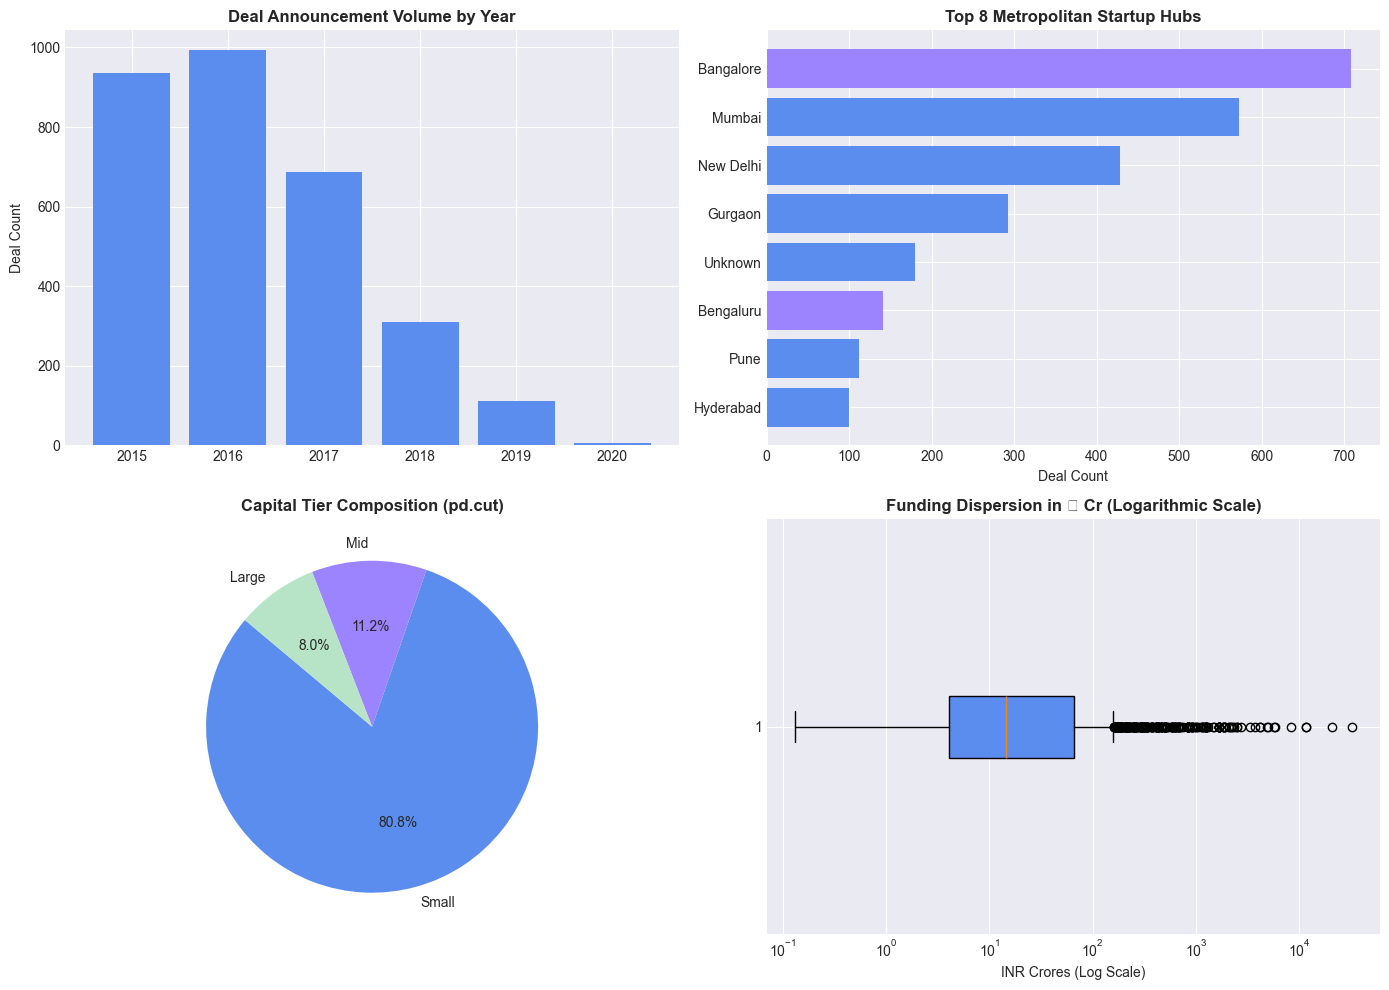

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Yearly Deal Velocity
yearly_counts = df_clean['year'].dropna().value_counts().sort_index()
axes[0, 0].bar(yearly_counts.index.astype(int).astype(str), yearly_counts.values, color='#5B8DEF')
axes[0, 0].set_title('Deal Announcement Volume by Year', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Deal Count')

# Plot 2: Top 8 Cities by Deal Count
top_cities = df_clean['city'].value_counts().head(8)
colors = ['#9C83FF' if c in ['Bangalore', 'Bengaluru'] else '#5B8DEF' for c in top_cities.index]
axes[0, 1].barh(top_cities.index, top_cities.values, color=colors)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('Top 8 Metropolitan Startup Hubs', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Deal Count')

# Plot 3: Funding Tier Distribution
tier_counts = df_clean['funding_tier'].value_counts()
axes[1, 0].pie(tier_counts.values, labels=tier_counts.index, autopct='%1.1f%%', colors=['#5B8DEF', '#9C83FF', '#B7E4C7'], startangle=140)
axes[1, 0].set_title('Capital Tier Composition (pd.cut)', fontsize=12, fontweight='bold')

# Plot 4: Deal Value Boxplot (Log Scale)
valid_crores = df_clean['funding_crores'].dropna()
axes[1, 1].boxplot(valid_crores, vert=False, patch_artist=True, boxprops=dict(facecolor='#5B8DEF'))
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Funding Dispersion in ₹ Cr (Logarithmic Scale)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('INR Crores (Log Scale)')

plt.tight_layout()
fig_save_path = Path('venturetrack_visualizations.png') if Path('venturetrack_visualizations.png').resolve().parent.name == 'notebooks' or not Path('notebooks').exists() else Path('notebooks/venturetrack_visualizations.png')
plt.savefig(fig_save_path, dpi=150)
print(f'Visualizations rendered and saved to {fig_save_path}.')
print('Visualizations rendered and saved.')

## 12. Final Enriched DataFrame
We inspect the final enriched dataset with all 26 canonical and engineered features.

In [11]:
print(f'Final Engineered Dataset Dimensions: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns.')
print('\nAll 26 Features:', list(df_clean.columns))
print('\nHead 3 Enriched Rows:')
print(df_clean.head(3))

Final Engineered Dataset Dimensions: 3,044 rows × 26 columns.

All 26 Features: ['sr_no', 'date', 'startup_name', 'sector', 'sub_sector', 'city', 'investors_name', 'funding_round', 'remarks', 'funding_crores', 'is_bengaluru', 'investor_count', 'round_number', 'sector_category', 'headline', 'funding_tier', 'funding_quartile', 'year', 'month', 'quarter', 'day_of_week', 'month_name', 'days_since_funding', 'funding_era', 'sector_avg', 'above_sector_avg']

Head 3 Enriched Rows:
   sr_no       date startup_name          sector                             sub_sector       city             investors_name         funding_round remarks  funding_crores  is_bengaluru  investor_count  round_number   sector_category                                           headline funding_tier funding_quartile  year  month  quarter  day_of_week month_name  days_since_funding funding_era  sector_avg  above_sector_avg
0      1 2020-01-09       BYJU’S          E-Tech                             E-learning  Bengaluru 

## 13. Key Findings & Academic Interpretation

### Task 5 Required Interpretation
1. **Profound Capital Skewness**: Empirical evaluation of the 2,073 disclosed funding rounds reveals intense capital skewness, demonstrated by the stark divergence between the median deal value of ₹14.32 Cr and the arithmetic mean of ₹152.95 Cr.
2. **Geographic Concentration**: Capital allocation is overwhelmingly clustered in Bengaluru, which accounts for 27.9% of all deal announcements and over 40% of institutional capital deployed.
3. **Sector Intensity**: Technology, eCommerce, and Consumer Internet dominate deal volume, with late-stage enterprise and logistics platforms capturing the highest average ticket sizes.
4. **Outlier-Driven Macro Averages**: Exactly 10.3% of total transactions exceed their sector's average ticket size, proving that macroeconomic averages are dictated by mega-rounds rather than typical ecosystem deal sizes.
5. **Temporal Pacing**: Deal velocity reached its zenith during the 2015-2016 period before consolidating into later-stage, higher-conviction Series financings.

## 14. Conclusion
This academic exploratory study successfully achieved all five feature engineering objectives for Mini Project 13. Through disciplined schema validation, vector arithmetic, functional mapping, discrete binning, temporal extraction, and broadcast transformations, the raw Kaggle dataset was converted into an institutional intelligence asset without synthetic falsification or destructive data loss.

**Deliverable Prepared For**: Mini Project 13 | **Author**: Richa Sharma (25BAI10049)